In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd

pd.set_option("display.max_columns", 30)


In [3]:
data = pd.read_csv('train.csv')

In [4]:
data

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,False,False,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,True,False,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,False,False,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,True,False,False,False,True,False,True,False,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33545,71911,9.0,0,0,109.80,14.5,False,True,False,True,False,False,False,False,False,True,True,False,False,False,False,0
33546,19648,47.0,0,0,88.61,30.8,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,0
33547,35550,3.0,0,0,89.68,16.2,True,False,False,True,False,False,False,False,False,True,True,False,False,False,False,0
33548,65453,56.0,1,0,82.44,27.8,True,False,False,False,True,True,False,False,False,False,False,True,False,False,True,0


## Opschonen


### Kolommen

Het model moet gefit worden op data die zo schoon mogelijk is. De features behoren geen ruis te geven. Daarom kijken we naar twee onderdelen

- Onmogelijke correlatie

Sommige informatie kan onmogelijk correleren, of zou niet moeten correleren met de predictor. In dit geval is het de ID kolom. Dit zijn willekeurige cijfers om elke rij te identificeren, alleen het model zal hier patronen proberen te ontdekken die niet bestaan, dit noem je ruis. Om deze reden zullen we de ID kolom weghalen



- Multicolineariteit

Kolommen die naar dummys worden omgezet hebben standaard een sterke correlatie met elkaar --> als het ene waar is, is het andere niet waar --> sterke negatieve correlatie. Dit zorgt ervoor dat de dummykolomen een sterkere weging krijgen zonder dat dat de bedoeling is. We kunnen dit voorkomen door per onderscheiding één klasse weg te halen, waardoor de ontbrekende klasse van toepassing is als de overige 'False' geven. Hieronder is een overzicht gemaakt van de klassen per variabele.


| Variabele | Categorieën |
|---|---|
| **Gender** | `gender_male`, `gender_female`, `gender_other` |
| **ever_married** | `ever_married_No`, `ever_married_Yes` |
| **work_type** | `Govt_job`, `Never_worked`, `Private`, `Self-employed`, `children` |
| **Residence_type** | `Rural`, `Urban` |
| **smoking_status** | `formerly_smoked`, `never_smoked`, `smokes`, `unknown` |

Bij de beschrijving van de opdracht is er aangegeven dat smoking_status al een verwijderde kolom heeft. Daarom hoeft deze variabele niet aangepast te worden.

In [5]:
dropcols = ['id', 'stroke', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

### Rijen

Om irrelevante rijen te verwijderen kijken we weer naar twee onderdelen

- Missende waarden door geen datagerelateerde reden --> MCAR

De dataset bevat geen missende waarden, dus hier hoeft niks aan te gebeuren.


- Onmogelijke/foute waarden

Hierbij kijken we of er extreem hoge/lage waarden zijn, of output die geen informatie geeft


#### Onmogelijke/foute waarden

In [15]:
type(data['age'][0])

numpy.float64

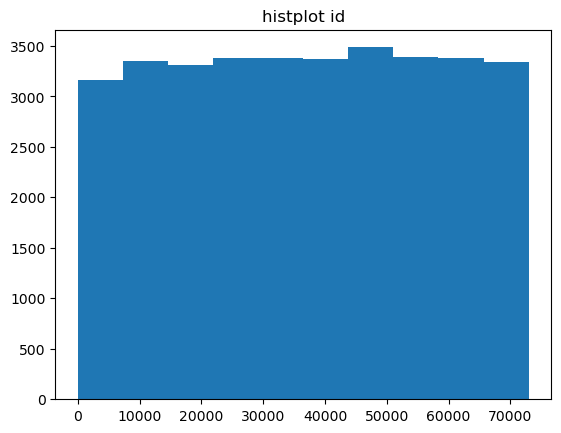

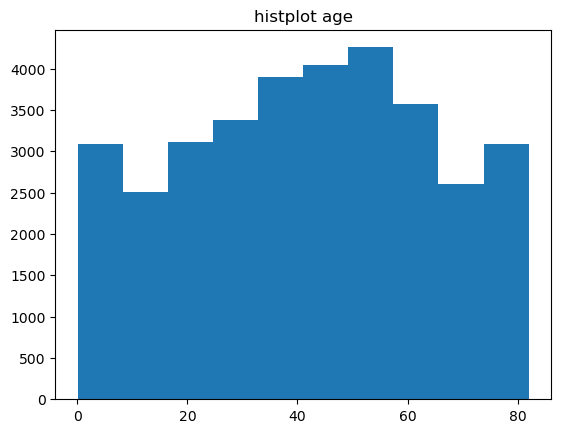

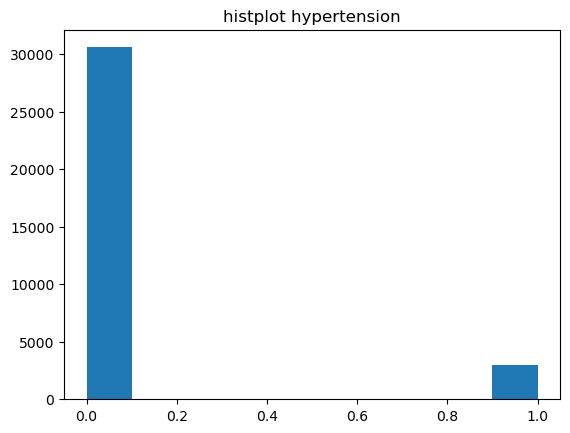

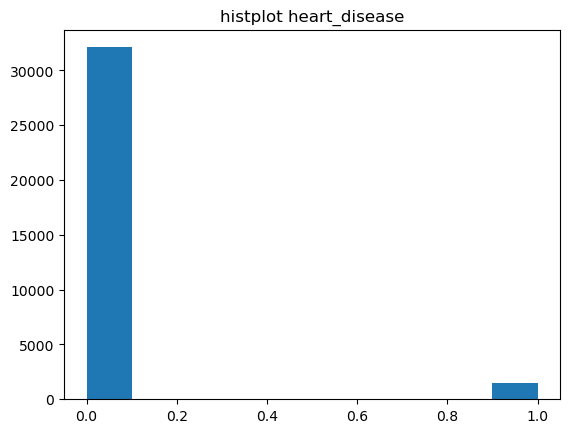

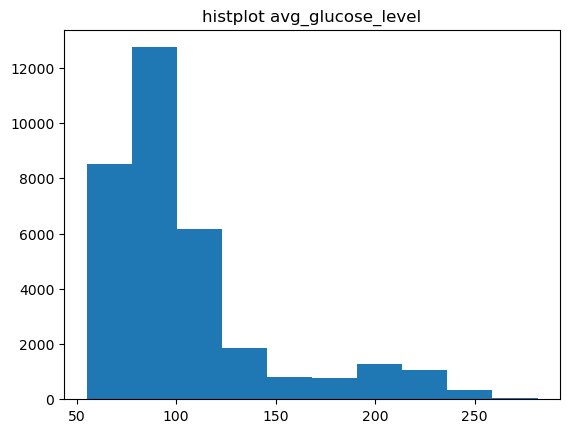

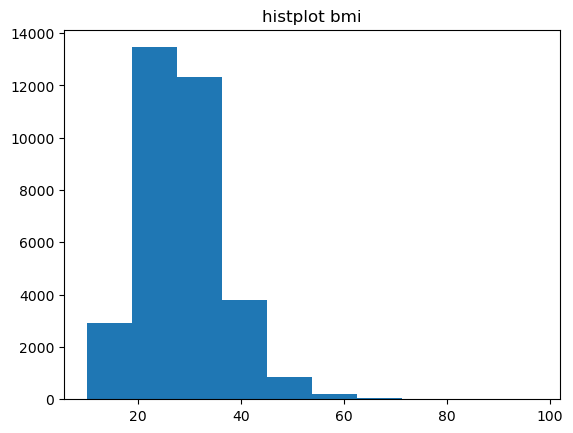

c:\Users\schur\anaconda3\Lib\site-packages\matplotlib\axes\_axes.py:7001: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)


TypeError: numpy boolean subtract, the `-` operator, is not supported, use the bitwise_xor, the `^` operator, or the logical_xor function instead.

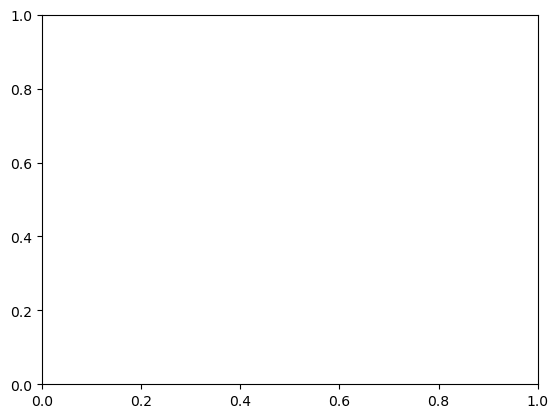

In [ ]:
for i in [col for col in list(data.columns) if data[col] == float or data[col] == int]:

    
    
    plt.hist(data[i])
    plt.title(f'histplot {i}')
    plt.show()


# Modellen


## Ensembles

### Random Forest

Dit is een ensemble decision trees parallel traint om variatie te verminderen. Er wordt gebruik gemaakt van bagging (bootstrap aggregation) om verschillende random combbinaties van waarden uit de dataset te halen om de verschillende bomen te trainen.

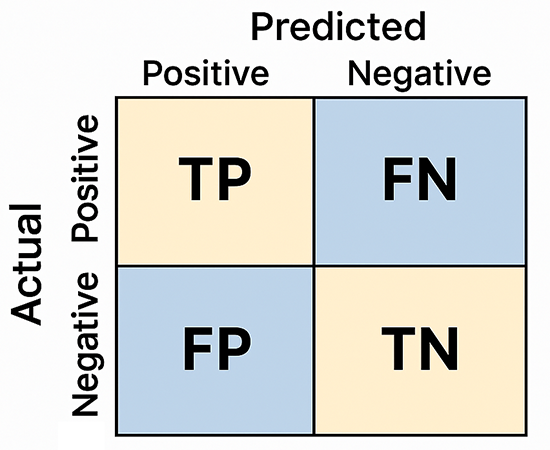